In [1]:
import pandas as pd

df = pd.read_csv('train.csv')
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [2]:
df.shape


(1460, 81)

In [3]:
df['SalePrice'].describe()


count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

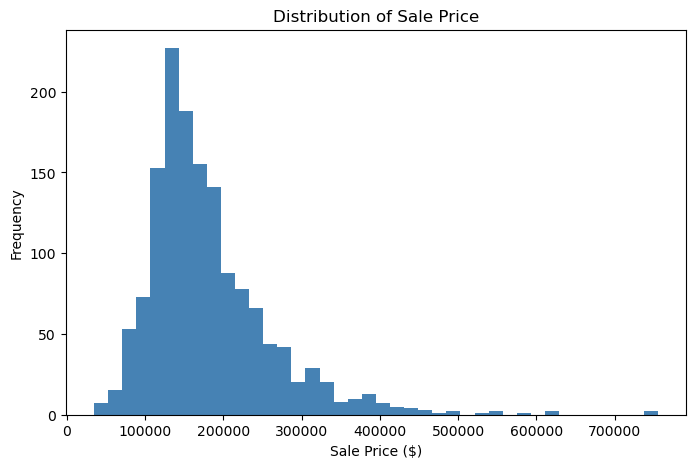

In [4]:
import matplotlib.pyplot as plt

df['SalePrice'].plot(kind='hist', bins=40, figsize=(8,5), color='steelblue')
plt.title('Distribution of Sale Price')
plt.xlabel('Sale Price ($)')
plt.show()


In [5]:
features = ['OverallQual', 'GrLivArea', 'GarageCars', 'TotalBsmtSF', 
            'FullBath', 'YearBuilt', 'BedroomAbvGr', 'Neighborhood']

data = df[features + ['SalePrice']].copy()
data.isnull().sum()

OverallQual     0
GrLivArea       0
GarageCars      0
TotalBsmtSF     0
FullBath        0
YearBuilt       0
BedroomAbvGr    0
Neighborhood    0
SalePrice       0
dtype: int64

## Feature Selection Reasoning

I selected these features because they're commonly understood to drive house price:

- OverallQual: overall material/finish quality rating which is directly tied to perceived value
- GrLivArea: above-ground living area (square footage) i.e bigger homes generally cost more
- GarageCars: garage capacity, a general approx for property size and convenience
- TotalBsmtSF: basement square footage
- FullBath: number of full bathrooms, in general more bathrooms usually means a larger and more pricier home
- YearBuilt: newer homes tend to sell for more due to modern new construction/less wear and tear.
- BedroomAbvGr: number of bedrooms ofcourse directly affects livability and increase no. of people to accomadate
- Neighborhood: location is one of the biggest known drivers of real estate price, good neighborhood makes the property expensive
    

In [7]:
# Fill any missing numeric values with median (shouldn't be many with these columns)
data = data.fillna(data.median(numeric_only=True))

# One-Hot Encode the categorical column (Neighborhood)
data = pd.get_dummies(data, columns=['Neighborhood'], drop_first=True)

data.shape

(1460, 32)

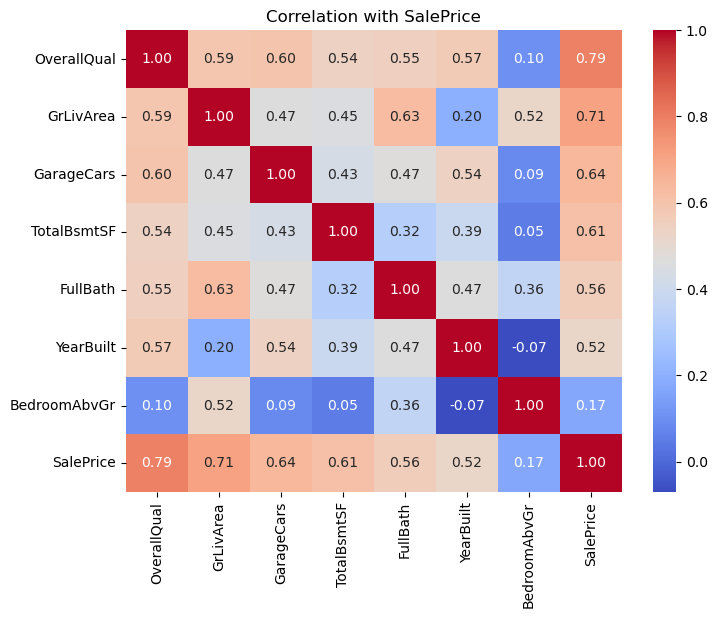

In [8]:
import seaborn as sns

plt.figure(figsize=(8,6))
sns.heatmap(data[features[:-1] + ['SalePrice']].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation with SalePrice')
plt.show()

In [9]:
from sklearn.model_selection import train_test_split

X = data.drop('SalePrice', axis=1)
y = data['SalePrice']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape, X_test.shape)

(1168, 31) (292, 31)


In [10]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [11]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MSE: {mse:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R² Score: {r2:.4f}")

MSE: 1,301,513,687.00
RMSE: 36,076.50
R² Score: 0.8303


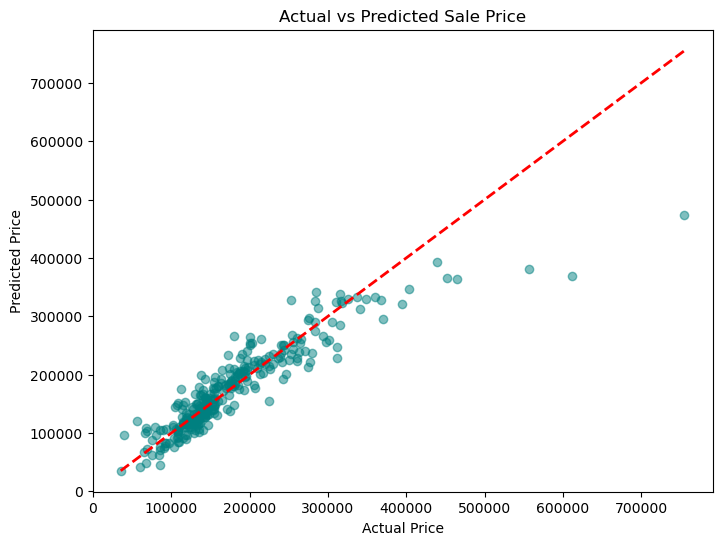

In [12]:
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.5, color='teal')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted Sale Price')
plt.show()


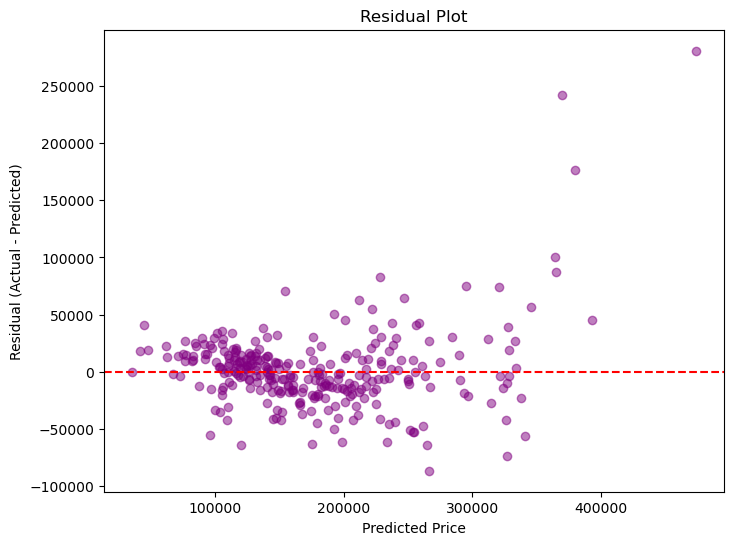

In [13]:
residuals = y_test - y_pred

plt.figure(figsize=(8,6))
plt.scatter(y_pred, residuals, alpha=0.5, color='purple')
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Predicted Price')
plt.ylabel('Residual (Actual - Predicted)')
plt.title('Residual Plot')
plt.show()

In [14]:
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
}).sort_values(by='Coefficient', ascending=False)

coefficients

,Feature,Coefficient
28,Neighborhood_StoneBr,74639.967469
22,Neighborhood_NridgHt,73020.057633
21,Neighborhood_NoRidge,71590.859871
30,Neighborhood_Veenker,63619.166906
10,Neighborhood_ClearCr,51672.454647
12,Neighborhood_Crawfor,48011.023004
29,Neighborhood_Timber,41021.378942
27,Neighborhood_Somerst,31126.869253
11,Neighborhood_CollgCr,25859.990146
9,Neighborhood_BrkSide,24943.517901


In [15]:
from sklearn.linear_model import Ridge, Lasso

ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)
ridge_r2 = r2_score(y_test, ridge.predict(X_test))

lasso = Lasso(alpha=1.0)
lasso.fit(X_train, y_train)
lasso_r2 = r2_score(y_test, lasso.predict(X_test))

print(f"Linear Regression R²: {r2:.4f}")
print(f"Ridge R²: {ridge_r2:.4f}")
print(f"Lasso R²: {lasso_r2:.4f}")

Linear Regression R²: 0.8303
Ridge R²: 0.8307
Lasso R²: 0.8304
